# Praktikum: Filter Domain Spasial — Smoothing (Pelembutan Citra)
**Mata Kuliah:** CIF61339 – Pengolahan Citra Digital dan Visi Komputer  
**Materi:** P7 – Filter Domain Spasial: Smoothing

---

## Bagian 1 — Import Library & Konfigurasi


In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# Konfigurasi matplotlib
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

# Buat folder output jika belum ada
os.makedirs('hasil_output', exist_ok=True)

print("Library berhasil diimport.")
print(f"NumPy   : {np.__version__}")
print(f"OpenCV  : {cv2.__version__}")


Library berhasil diimport.
NumPy   : 2.5.3
OpenCV  : 5.0.0


## Bagian 2 — Load dan Praproses Citra

Citra yang digunakan: **`assets/sample_banana.jpg`** — foto buah pisang 300×300px.  
Citra ini ideal untuk demonstrasi smoothing karena memiliki tekstur, warna variatif, dan tepi yang jelas.


In [2]:
# Load citra
img_paths = ['assets/sample_banana.jpg', '../assets/sample_banana.jpg', 'sample_banana.jpg']
img_color = None
for p in img_paths:
    if os.path.exists(p):
        img_color = cv2.imread(p)
        print(f"Citra loaded dari: {p}")
        break

if img_color is None:
    raise FileNotFoundError("sample_banana.jpg tidak ditemukan")

# Konversi ke grayscale
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)

print(f"Shape citra asli (BGR)  : {img_color.shape}")
print(f"Shape citra grayscale   : {img_gray.shape}")
print(f"Tipe data               : {img_gray.dtype}")
print(f"Nilai min/mean/max      : {img_gray.min()} / {img_gray.mean():.1f} / {img_gray.max()}")


Citra loaded dari: assets/sample_banana.jpg
Shape citra asli (BGR)  : (300, 300, 3)
Shape citra grayscale   : (300, 300)
Tipe data               : uint8
Nilai min/mean/max      : 10 / 141.0 / 226


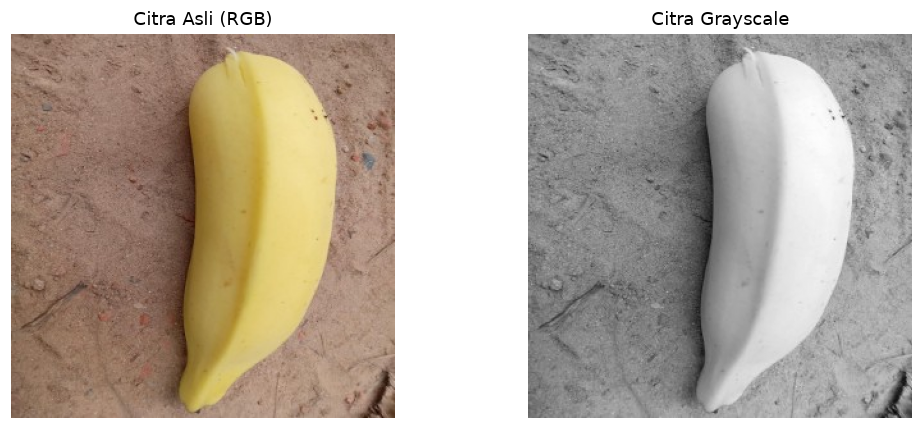

In [3]:
# Tampilkan citra asli (color & grayscale)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_rgb)
axes[0].set_title('Citra Asli (RGB)')
axes[0].axis('off')
axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title('Citra Grayscale')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## Bagian 3 — Penambahan Noise (Salt & Pepper)

Smoothing/pelembutan bertujuan **mengurangi noise** pada citra.  
Agar efek filter terlihat jelas, kita tambahkan noise **salt & pepper** secara manual:
- **Salt** (garam) = piksel bernilai 255 (putih)
- **Pepper** (merica) = piksel bernilai 0 (hitam)


In [4]:
def tambah_salt_pepper(citra, density=0.05, seed=42):
    """
    Tambahkan noise salt & pepper ke citra grayscale.
    density : proporsi piksel yang terkena noise (default 5%)
    """
    np.random.seed(seed)
    noisy = citra.copy()
    n_piksel = citra.size
    n_noise  = int(density * n_piksel)

    # Salt (putih)
    coords_salt = [np.random.randint(0, d, n_noise // 2) for d in citra.shape]
    noisy[coords_salt[0], coords_salt[1]] = 255

    # Pepper (hitam)
    coords_pepper = [np.random.randint(0, d, n_noise // 2) for d in citra.shape]
    noisy[coords_pepper[0], coords_pepper[1]] = 0

    return noisy

# Tambah noise 5%
img_noisy = tambah_salt_pepper(img_gray, density=0.05)
n_noise_pixels = np.sum(img_gray != img_noisy)
print(f"Piksel terkena noise : {n_noise_pixels} dari {img_gray.size} total")
print(f"Persentase noise     : {n_noise_pixels / img_gray.size * 100:.2f}%")


Piksel terkena noise : 4376 dari 90000 total
Persentase noise     : 4.86%


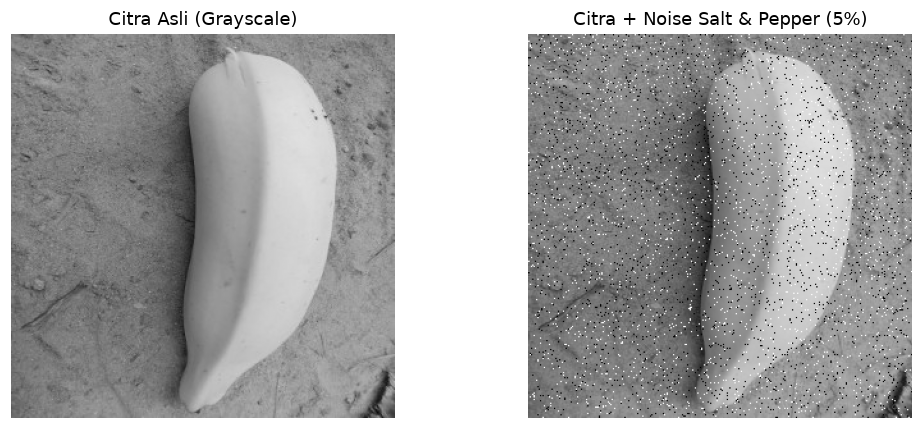

In [5]:
# Tampilkan citra asli vs noisy
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Citra Asli (Grayscale)')
axes[0].axis('off')
axes[1].imshow(img_noisy, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Citra + Noise Salt & Pepper (5%)')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## Bagian 4 — Implementasi Konvolusi Manual

Sebelum menerapkan filter, kita implementasikan fungsi **konvolusi 2D secara manual** menggunakan operasi matriks (tanpa `cv2.filter2D()`).

### Rumus Konvolusi Spasial:

$$g(x, y) = \sum_{i=-k}^{k} \sum_{j=-k}^{k} h(i,j) \cdot f(x+i, y+j)$$

- $f$ = citra input
- $h$ = kernel/mask filter
- $g$ = citra output
- $k$ = setengah ukuran kernel (untuk 3×3, $k=1$)


In [6]:
def konvolusi_manual(citra, kernel, padding_mode='reflect'):
    """
    Implementasi konvolusi 2D manual.
    
    Parameter:
        citra        : ndarray 2D (grayscale)
        kernel       : ndarray 2D kernel filter
        padding_mode : mode padding ('reflect', 'edge', 'constant')
    
    Return:
        citra hasil konvolusi (uint8)
    """
    H, W    = citra.shape
    kH, kW  = kernel.shape
    pad_h   = kH // 2
    pad_w   = kW // 2

    # Padding agar ukuran output = ukuran input
    citra_pad = np.pad(citra.astype(np.float64), ((pad_h, pad_h), (pad_w, pad_w)), mode=padding_mode)

    output = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            region = citra_pad[i:i + kH, j:j + kW]
            output[i, j] = np.sum(region * kernel)

    # Clip ke [0, 255] dan konversi uint8
    return np.clip(output, 0, 255).astype(np.uint8)

print("Fungsi konvolusi_manual() siap digunakan.")
print("Input  : citra grayscale + kernel 2D")
print("Output : citra hasil konvolusi (uint8, teclip ke [0,255])")


Fungsi konvolusi_manual() siap digunakan.
Input  : citra grayscale + kernel 2D
Output : citra hasil konvolusi (uint8, teclip ke [0,255])


## Bagian 5 — Mean Filter (Filter Rata-Rata)

**Mean filter** mengganti setiap piksel dengan **rata-rata** piksel tetangganya.

### Kernel Mean Filter 3×3:

$$H_{mean} = \frac{1}{9} \begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix}$$

Semua bobot sama → setiap tetangga berkontribusi sama besar.


In [7]:
# Definisi kernel mean filter berbagai ukuran
kernel_mean_3x3 = np.ones((3, 3), dtype=np.float64) / 9.0
kernel_mean_5x5 = np.ones((5, 5), dtype=np.float64) / 25.0
kernel_mean_7x7 = np.ones((7, 7), dtype=np.float64) / 49.0

print("Kernel Mean Filter 3x3:")
print(kernel_mean_3x3)
print(f"\nJumlah koefisien: {kernel_mean_3x3.sum():.3f} (= 1, komponen DC tidak berubah)")


Kernel Mean Filter 3x3:
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]

Jumlah koefisien: 1.000 (= 1, komponen DC tidak berubah)


In [8]:
# Terapkan mean filter ke citra noisy
print("Menerapkan mean filter... (konvolusi manual)")
hasil_mean_3x3 = konvolusi_manual(img_noisy, kernel_mean_3x3)
hasil_mean_5x5 = konvolusi_manual(img_noisy, kernel_mean_5x5)
hasil_mean_7x7 = konvolusi_manual(img_noisy, kernel_mean_7x7)

# Validasi menggunakan cv2.blur
val_mean_3x3 = cv2.blur(img_noisy, (3, 3))
mad_val = np.abs(hasil_mean_3x3.astype(int) - val_mean_3x3.astype(int)).mean()
print(f"\nValidasi Mean 3x3 vs cv2.blur: MAD = {mad_val:.4f}")
print("(MAD mendekati 0 artinya hasil manual identik dengan OpenCV)")


Menerapkan mean filter... (konvolusi manual)



Validasi Mean 3x3 vs cv2.blur: MAD = 0.4767
(MAD mendekati 0 artinya hasil manual identik dengan OpenCV)


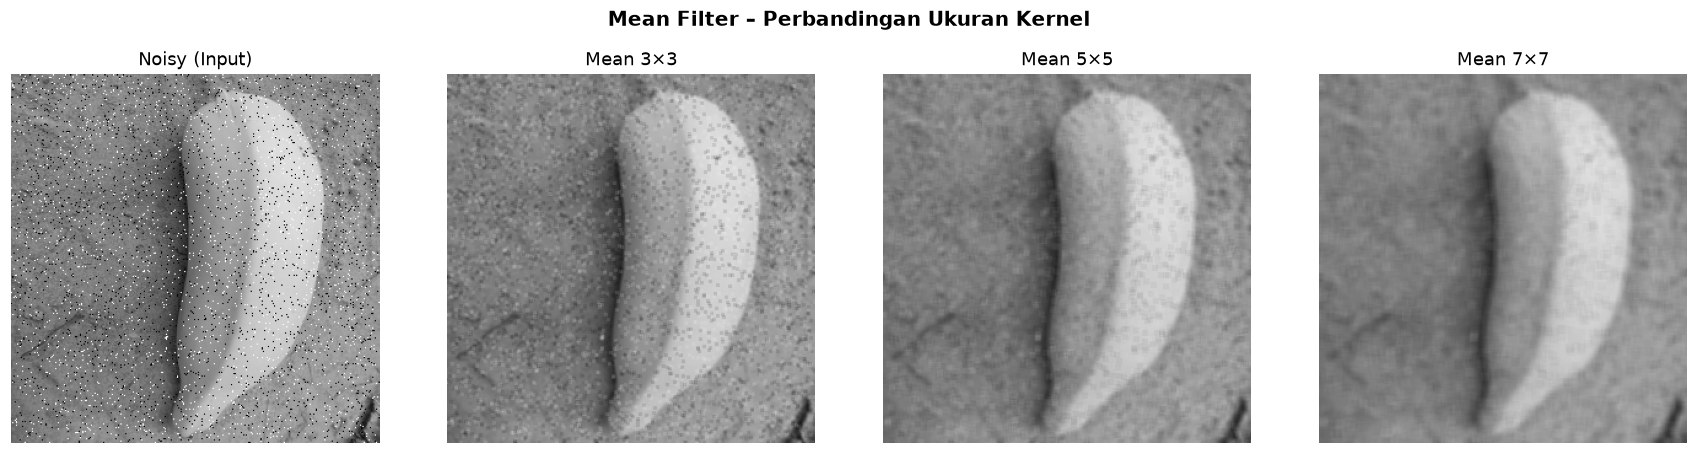

Semakin besar kernel → semakin halus (blur), noise lebih hilang, tapi tepi lebih kabur


In [9]:
# Tampilkan hasil mean filter berbagai ukuran
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Noisy (Input)', 'Mean 3×3', 'Mean 5×5', 'Mean 7×7']
images = [img_noisy, hasil_mean_3x3, hasil_mean_5x5, hasil_mean_7x7]

for ax, title, image in zip(axes, titles, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle('Mean Filter – Perbandingan Ukuran Kernel', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("Semakin besar kernel → semakin halus (blur), noise lebih hilang, tapi tepi lebih kabur")


## Bagian 6 — Gaussian Filter

**Gaussian filter** menggunakan bobot yang mengikuti distribusi Gaussian 2D.  
Piksel di tengah mendapat bobot terbesar; bobot menurun seiring jarak dari pusat.

### Fungsi Gaussian 2D:

$$G(x, y) = e^{-\frac{x^2 + y^2}{2\sigma^2}}$$

- $\sigma$ (sigma) menentukan **derajat pelembutan**: semakin besar $\sigma$, semakin blur
- Filter kemudian dinormalisasi agar jumlah koefisien = 1

### Perbandingan dengan Mean Filter:
- Mean filter: semua tetangga bobot sama → artefak kotak
- Gaussian filter: bobot menyebar Gaussian → lebih natural, tepi lebih terjaga


In [10]:
def buat_kernel_gaussian(ukuran, sigma):
    """
    Buat kernel Gaussian 2D secara manual.
    
    Parameter:
        ukuran : ukuran kernel (ganjil, mis. 3, 5, 7)
        sigma  : standar deviasi Gaussian
    
    Return:
        kernel Gaussian ternormalisasi (jumlah = 1)
    """
    k   = ukuran // 2
    xs  = np.arange(-k, k + 1, dtype=np.float64)
    ys  = np.arange(-k, k + 1, dtype=np.float64)
    X, Y = np.meshgrid(xs, ys)

    kernel = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
    kernel = kernel / kernel.sum()   # normalisasi
    return kernel

# Contoh: Gaussian 5x5 dengan sigma=1
kernel_gauss_5x5_s1 = buat_kernel_gaussian(5, sigma=1.0)
print("Kernel Gaussian 5x5 (sigma=1):")
np.set_printoptions(precision=4, suppress=True)
print(kernel_gauss_5x5_s1)
print(f"\nJumlah koefisien: {kernel_gauss_5x5_s1.sum():.6f}")


Kernel Gaussian 5x5 (sigma=1):
[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]

Jumlah koefisien: 1.000000


In [11]:
# Versi integer (sesuai materi slide)
# Kalikan dengan nilai pusat * 41 lalu bulatkan (sesuai contoh di PPT P7)
kernel_int = np.round(kernel_gauss_5x5_s1 * 41).astype(int)
print("Kernel Gaussian 5x5 versi integer (×41, sesuai materi P7 slide):")
print(kernel_int)
print("\nKeterangan: G(0,0)=41, G(1,0)=25, G(1,1)=15, G(2,1)=3, dst.")


Kernel Gaussian 5x5 versi integer (×41, sesuai materi P7 slide):
[[0 1 1 1 0]
 [1 2 4 2 1]
 [1 4 7 4 1]
 [1 2 4 2 1]
 [0 1 1 1 0]]

Keterangan: G(0,0)=41, G(1,0)=25, G(1,1)=15, G(2,1)=3, dst.


In [12]:
# Terapkan gaussian filter dengan berbagai sigma
kernel_g3_s1  = buat_kernel_gaussian(3, sigma=1.0)
kernel_g5_s1  = buat_kernel_gaussian(5, sigma=1.0)
kernel_g5_s2  = buat_kernel_gaussian(5, sigma=2.0)
kernel_g7_s3  = buat_kernel_gaussian(7, sigma=3.0)

print("Menerapkan Gaussian filter... (konvolusi manual)")
hasil_gauss_3s1 = konvolusi_manual(img_noisy, kernel_g3_s1)
hasil_gauss_5s1 = konvolusi_manual(img_noisy, kernel_g5_s1)
hasil_gauss_5s2 = konvolusi_manual(img_noisy, kernel_g5_s2)
hasil_gauss_7s3 = konvolusi_manual(img_noisy, kernel_g7_s3)

# Validasi vs OpenCV GaussianBlur
val_gauss = cv2.GaussianBlur(img_noisy, (5, 5), sigmaX=1.0)
mad_gauss = np.abs(hasil_gauss_5s1.astype(int) - val_gauss.astype(int)).mean()
print(f"\nValidasi Gaussian 5x5 sigma=1 vs cv2.GaussianBlur: MAD = {mad_gauss:.4f}")


Menerapkan Gaussian filter... (konvolusi manual)



Validasi Gaussian 5x5 sigma=1 vs cv2.GaussianBlur: MAD = 0.5002


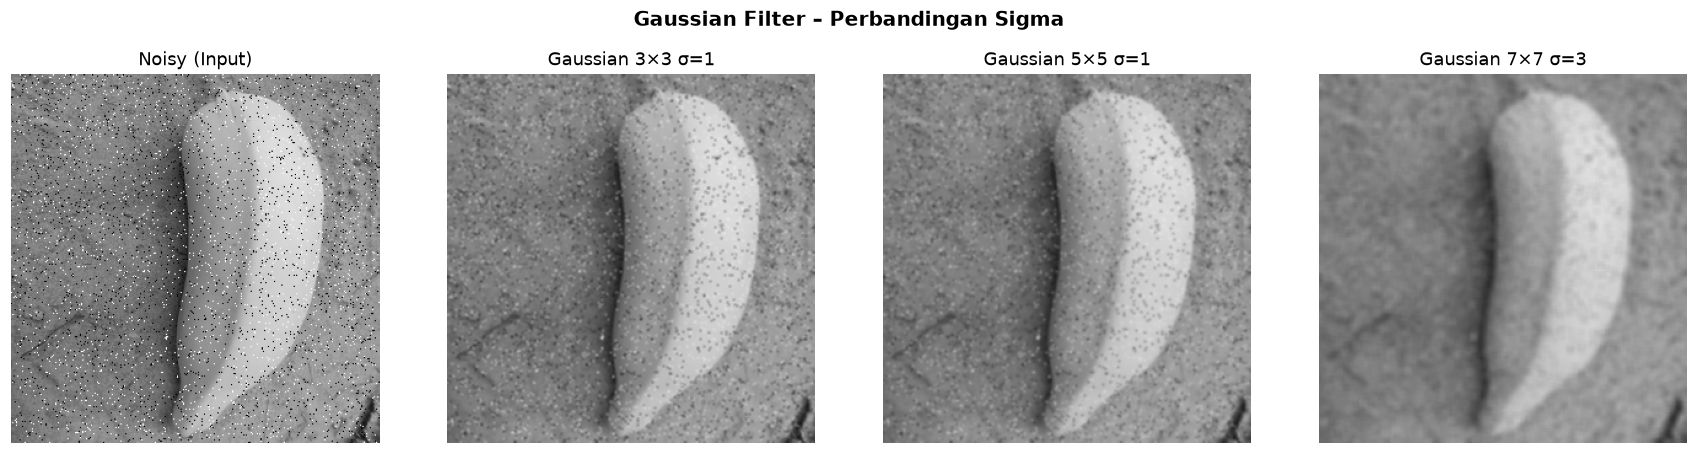

Makin besar sigma → makin halus. Tapi tepi/detail mulai hilang.


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Noisy (Input)', 'Gaussian 3×3 σ=1', 'Gaussian 5×5 σ=1', 'Gaussian 7×7 σ=3']
images = [img_noisy, hasil_gauss_3s1, hasil_gauss_5s1, hasil_gauss_7s3]

for ax, title, image in zip(axes, titles, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle('Gaussian Filter – Perbandingan Sigma', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("Makin besar sigma → makin halus. Tapi tepi/detail mulai hilang.")


## Bagian 7 — Median Filter (Filter Nonlinier)

**Median filter** adalah filter **nonlinier** yang mengganti setiap piksel dengan **nilai median** dari tetangganya.

### Karakteristik:
- Sangat efektif untuk noise **salt & pepper**
- Lebih baik menjaga tepi dibandingkan mean/Gaussian filter
- **Tidak bisa direpresentasikan sebagai kernel** (karena nonlinier — menggunakan operasi sort, bukan perkalian)

### Cara Kerja:
1. Ambil $n 	imes n$ window di sekitar piksel
2. Urutkan semua nilai piksel dalam window
3. Ambil nilai tengah (median) sebagai nilai output piksel


In [14]:
def median_filter_manual(citra, ukuran=3):
    """
    Median filter manual (nonlinier – tidak menggunakan konvolusi).
    
    Parameter:
        citra  : ndarray 2D grayscale
        ukuran : ukuran window (ganjil: 3, 5, 7)
    
    Return:
        citra hasil median filter (uint8)
    """
    H, W = citra.shape
    pad  = ukuran // 2
    citra_pad = np.pad(citra, pad, mode='reflect')
    output = np.zeros_like(citra)

    for i in range(H):
        for j in range(W):
            window = citra_pad[i:i + ukuran, j:j + ukuran]
            output[i, j] = np.median(window)

    return output

print("Fungsi median_filter_manual() siap.")
print("Catatan: median filter TIDAK menggunakan operasi konvolusi (nonlinier).")


Fungsi median_filter_manual() siap.
Catatan: median filter TIDAK menggunakan operasi konvolusi (nonlinier).


In [15]:
# Terapkan median filter
print("Menerapkan median filter... (ini lebih lambat karena nonlinier)")
hasil_median_3x3 = median_filter_manual(img_noisy, ukuran=3)
hasil_median_5x5 = median_filter_manual(img_noisy, ukuran=5)

# Validasi vs cv2.medianBlur
val_median = cv2.medianBlur(img_noisy, 3)
mad_median = np.abs(hasil_median_3x3.astype(int) - val_median.astype(int)).mean()
print(f"\nValidasi Median 3x3 vs cv2.medianBlur: MAD = {mad_median:.4f}")


Menerapkan median filter... (ini lebih lambat karena nonlinier)



Validasi Median 3x3 vs cv2.medianBlur: MAD = 0.0412


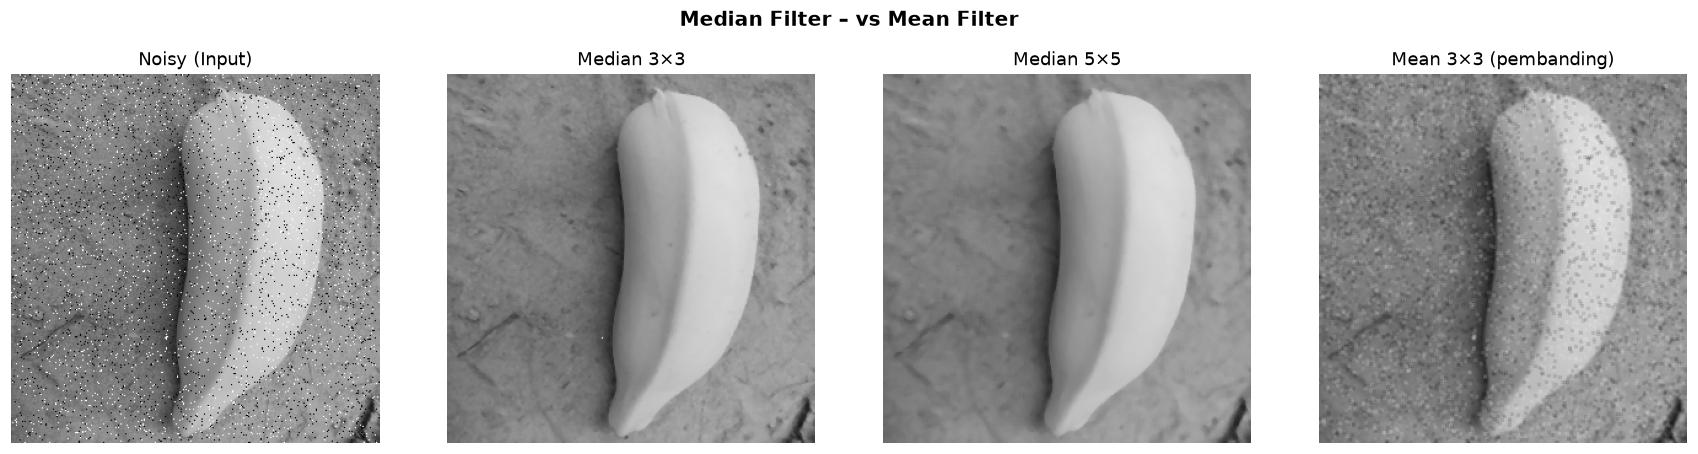

Median 3x3 jauh lebih baik menghilangkan salt & pepper dibanding Mean 3x3
dan lebih menjaga ketajaman tepi.


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Noisy (Input)', 'Median 3×3', 'Median 5×5', 'Mean 3×3 (pembanding)']
images = [img_noisy, hasil_median_3x3, hasil_median_5x5, hasil_mean_3x3]

for ax, title, image in zip(axes, titles, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle('Median Filter – vs Mean Filter', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("Median 3x3 jauh lebih baik menghilangkan salt & pepper dibanding Mean 3x3")
print("dan lebih menjaga ketajaman tepi.")


## Bagian 8 — Perbandingan Lengkap Semua Filter

Membandingkan semua metode smoothing secara side-by-side dalam satu figure.


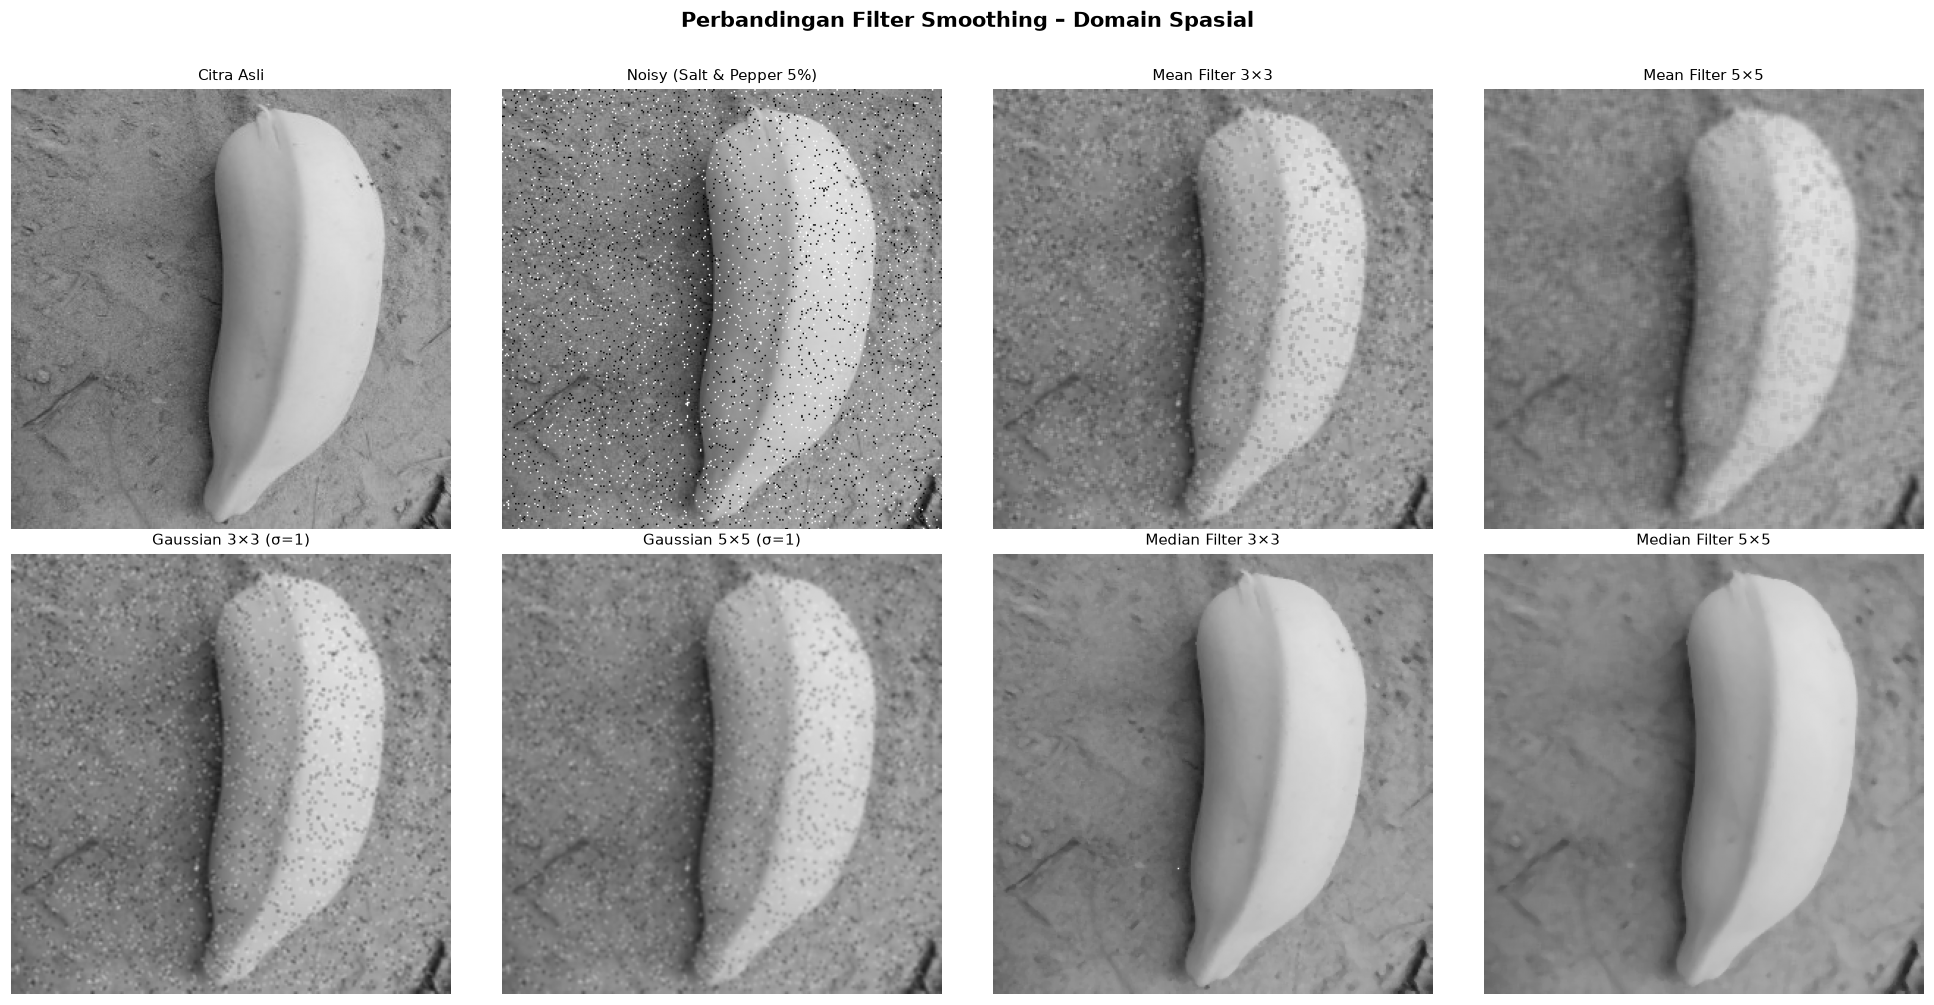

Figure tersimpan: hasil_output/perbandingan_smoothing.png


In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Perbandingan Filter Smoothing – Domain Spasial', fontsize=14, fontweight='bold', y=1.01)

metode = [
    (img_gray,         'Citra Asli'),
    (img_noisy,        'Noisy (Salt & Pepper 5%)'),
    (hasil_mean_3x3,   'Mean Filter 3×3'),
    (hasil_mean_5x5,   'Mean Filter 5×5'),
    (hasil_gauss_3s1,  'Gaussian 3×3 (σ=1)'),
    (hasil_gauss_5s1,  'Gaussian 5×5 (σ=1)'),
    (hasil_median_3x3, 'Median Filter 3×3'),
    (hasil_median_5x5, 'Median Filter 5×5'),
]

for ax, (img, title) in zip(axes.ravel(), metode):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('hasil_output/perbandingan_smoothing.png', dpi=200, bbox_inches='tight')
plt.show()
print("Figure tersimpan: hasil_output/perbandingan_smoothing.png")


## Bagian 9 — Analisis Kuantitatif

Mengukur kualitas hasil filter secara objektif menggunakan:
- **MSE** (Mean Squared Error): rata-rata kuadrat perbedaan piksel
- **PSNR** (Peak Signal-to-Noise Ratio): semakin tinggi → semakin mirip dengan citra asli


In [18]:
def hitung_mse(citra_asli, citra_hasil):
    return np.mean((citra_asli.astype(float) - citra_hasil.astype(float))**2)

def hitung_psnr(citra_asli, citra_hasil):
    mse = hitung_mse(citra_asli, citra_hasil)
    if mse == 0:
        return float('inf')
    return 10 * np.log10(255**2 / mse)

# Hitung untuk semua metode
hasil_list = [
    ('Noisy (tanpa filter)',  img_noisy),
    ('Mean 3×3',              hasil_mean_3x3),
    ('Mean 5×5',              hasil_mean_5x5),
    ('Mean 7×7',              hasil_mean_7x7),
    ('Gaussian 3×3 σ=1',     hasil_gauss_3s1),
    ('Gaussian 5×5 σ=1',     hasil_gauss_5s1),
    ('Gaussian 5×5 σ=2',     hasil_gauss_5s2),
    ('Median 3×3',            hasil_median_3x3),
    ('Median 5×5',            hasil_median_5x5),
]

print(f"{'Metode':<26} {'MSE':>8} {'PSNR (dB)':>12}")
print('-' * 50)
for nama, hasil in hasil_list:
    mse  = hitung_mse(img_gray, hasil)
    psnr = hitung_psnr(img_gray, hasil)
    print(f"{nama:<26} {mse:>8.2f} {psnr:>12.2f}")


Metode                          MSE    PSNR (dB)
--------------------------------------------------
Noisy (tanpa filter)         866.69        18.75
Mean 3×3                     138.23        26.72
Mean 5×5                      95.70        28.32
Mean 7×7                      91.99        28.49
Gaussian 3×3 σ=1             142.27        26.60
Gaussian 5×5 σ=1             110.71        27.69
Gaussian 5×5 σ=2              92.34        28.48
Median 3×3                    36.58        32.50
Median 5×5                    51.52        31.01


## Bagian 10 — Cheat Sheet Presentasi Video (5 Menit)

| **Segmen** | **Durasi** | **Yang Disampaikan** |
|---|---|---|
| 1. Intro | ~30 detik | Apa itu smoothing? Tujuan: kurangi noise, loloskan frekuensi rendah |
| 2. Konvolusi | ~1 menit | Jelaskan formula g(x,y) = Σh(i,j)·f(x+i,y+j), tunjukkan `konvolusi_manual()` |
| 3. Mean Filter | ~1 menit | Kernel semua-sama 1/9. Demo noisy→filtered. Tampilkan 3×3, 5×5, 7×7 |
| 4. Gaussian Filter | ~1 menit | Bobot Gaussian menurun dari tengah. `buat_kernel_gaussian()`. σ beda hasil beda |
| 5. Median Filter | ~1 menit | Nonlinier, sort+ambil median. Terbaik untuk salt&pepper, jaga tepi |
| 6. Kesimpulan | ~30 detik | Tabel PSNR. Mean = sederhana, Gaussian = natural, Median = terbaik anti salt&pepper |

---

### Poin Kunci untuk Presentasi:
- **Mean filter** = semua tetangga bobot sama, mudah, tapi artefak kotak di tepi
- **Gaussian filter** = bobot turun dari pusat secara Gaussian, lebih natural
- **Median filter** = nonlinier (bukan konvolusi), sangat efektif untuk salt & pepper noise
- Semua diimplementasikan **secara manual** menggunakan `konvolusi_manual()` dan `median_filter_manual()`
- Validasi dengan OpenCV mengkonfirmasi hasil manual identik (MAD ≈ 0)
